## Bayesian vs Frequentist Statistics: What's the difference?

Any statistical paradigm, Bayesian or otherwise, involves at least the following:

1. Some **unknown quantities** about which we are interested in learning or testing. We call these *parameters*.
2. Some **data** which have been observed, and hopefully contain information about (1).
3. One or more **models** that relate the data to the parameters, and is the instrument that is used to learn.


### The Frequentist World View


- The data that have been observed are considered **random**, because they are realizations of random processes, and hence will vary each time one goes to observe the system.
- Model parameters are considered **fixed**. The parameters' values are unknown, but they are fixed, and so we *condition* on them.

In mathematical notation, this implies a (very) general model of the following form:

$$f(y | \theta)$$

Here, the model $f$ accepts data values $y$ as an argument, conditional on particular values of $\theta$.


Frequentist inference typically involves deriving **estimators** for the unknown parameters. Estimators are formulae that return estimates for particular estimands, as a function of data. They are selected based on some chosen optimality criterion, such as *unbiasedness*, *variance minimization*, or *efficiency*.

> For example, lets say that we have collected some data on the prevalence of autism spectrum disorder (ASD) in some defined population. Our sample includes $n$ sampled children, $y$ of them having been diagnosed with autism. A frequentist estimator of the prevalence $p$ is:

> $$\hat{p} = \frac{y}{n}$$

> Why this particular function? Because it can be shown to be unbiased and minimum-variance.

It is important to note that new estimators need to be derived for every estimand that is introduced.

### The Bayesian World View


- Data are considered **fixed**. They used to be random, but once they were written into your lab notebook/spreadsheet/Jupyter notebook they do not change.
- Model parameters themselves may not be random, but Bayesians use probability distribtutions to describe their uncertainty in parameter values, and are therefore treated as **random**. In some cases, it is useful to consider parameters as having been sampled from probability distributions.

This implies the following form:

$$p(\theta | y)$$

This formulation used to be referred to as ***inverse probability***, because it infers from observations to parameters, or from effects to causes.

Bayesians do not seek new estimators for every estimation problem they encounter. There is only one estimator for Bayesian inference: **Bayes' Formula**.

# Computational Methods in Bayesian Analysis

The process of conducting Bayesian inference can be broken down into three general steps (Gelman *et al.* 2013):


### Step 1: Specify a probability model

As was noted above, Bayesian statistics involves using probability models to solve problems. So, the first task is to *completely specify* the model in terms of probability distributions. This includes everything: unknown parameters, data, covariates, missing data, predictions. All must be assigned some probability density.

This step involves making choices.

- what is the form of the sampling distribution of the data?
- what form best describes our uncertainty in the unknown parameters?

### Step 2: Calculate a posterior distribution

The mathematical form $p(\theta | y)$ that we associated with the Bayesian approach is referred to as a **posterior distribution**.

> posterior /pos·ter·i·or/ (pos-tēr´e-er) later in time; subsequent.

Why posterior? Because it tells us what we know about the unknown $\theta$ *after* having observed $y$.

This posterior distribution is formulated as a function of the probability model that was specified in Step 1. Usually, we can write it down but we cannot calculate it analytically. In fact, the difficulty inherent in calculating the posterior distribution for most models of interest is perhaps the major contributing factor for the lack of widespread adoption of Bayesian methods for data analysis. Various strategies for doing so comprise this tutorial.

**But**, once the posterior distribution is calculated, you get a lot for free:

- point estimates
- credible intervals
- quantiles
- predictions



### Step 3: Check your model

Though frequently ignored in practice, it is critical that the model and its outputs be assessed before using the outputs for inference. Models are specified based on assumptions that are largely unverifiable, so the least we can do is examine the output in detail, relative to the specified model and the data that were used to fit the model.

Specifically, we must ask:

- does the model fit data?
- are the conclusions reasonable?
- are the outputs sensitive to changes in model structure?


## Example: binomial calculation

Binomial model is suitable for data that are generated from a sequence of exchangeable Bernoulli trials. These data can be summarized by $y$, the number of times the event of interest occurs, and $n$, the total number of trials. The model parameter is the expected proportion of trials that an event occurs.

$$p(Y|\theta) = \frac{n!}{y! (n-y)!} \theta^{y} (1-\theta)^{n-y}$$

where $y \in \{0, 1, \ldots, n\}$ and $p \in [0, 1]$.

To perform Bayesian inference, we require the specification of a prior distribution. A reasonable choice is a uniform prior on [0,1] which has two implications:

1. makes all probability values equally probable *a priori*
2. makes calculation of the posterior easy

The second task in performing Bayesian inference is, given a fully-specified model, to calculate a posterior distribution. As we have specified the model, we can calculate a posterior distribution up to a proportionality constant (that is, a probability distribution that is **unnormalized**):

$$P(\theta | n, y) \propto P(y | n, \theta) P(\theta) = \theta^y (1-\theta)^{n-y}$$

We can present different posterior distributions as a function of different realized data.

We can also calculate posterior estimates for $\theta$ by maximizing the unnormalized posterior using optimization.

In [1]:
##### Installing packages

import numpy as np
import matplotlib.pyplot as plt
import os
# os.environ["PATH"] += os.pathsep + r'C:\Users\user\Downloads\windows_10_msbuild_Release_graphviz-7.1.0-win32\Graphviz\bin'

# The total probability law:

### Suppose we have to basketball players, one hit the basket with probability 0.6, and the other with 0.7.
### One of them will come shoot the basket, but we don't know which one. The first one will shoot with probability 0.25 and the second with 0.75.
### What is the chance that the shoot will hit the basket?
### A is the shoot will hit the basket.
### $B_1$ is the event that the first player will shoot
### $B_2$ is the event that the second player will shoot

$$ P(A) = P(A|B_1)*P(B_1)+ P(A|B_2)*P(B_2) = \sum_{i=1}^2P(A|B_i)*P(B_i) = 0.6*0.25+0.7*0.75 = 0.675$$

### Suppose we don't know who shot the ball, but we know that it went in. What is the probability that player 1 shot it?

### In other words, given that the ball went in, what is the probability that player 1 shot it?

### Formally,

### $$ P(B_1|A)= ? $$

### $$ P(B_1|A)= \frac{P(A|B_1)P(B_1)}{P(A)} = \frac{0.6*0.25}{0.675} = 0.22222  $$

## Baseball example

### Just prior

## $$ (A|B) = P(B|A)*P(A)/P(B) $$

## Beta Distribution

### $$ \theta \sim Beta(\alpha, \beta) $$

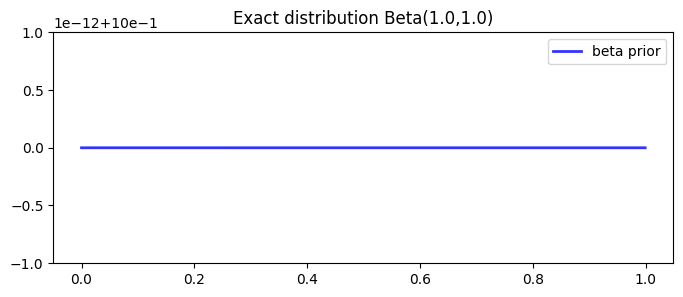

In [2]:
import scipy
from scipy import stats

## Uniform 
alpha = 1
beta = 1

# Baseball prior
# alpha = 81
# beta = 219

plt.figure(figsize = (8,3))
plt.title("Exact distribution Beta(%0.1f,%0.1f)"%(alpha,beta))
r=np.arange(0.,1.00,.001)
# plt.xlim(0.0,0.2)
# plt.ylim(0.,19.)
# plt.hist(samples_for_hist, density = True, bins =30)
plt.plot(r, scipy.stats.beta.pdf(r, alpha, beta), 'b-', lw=2, alpha=0.8, label='beta prior')
# plt.plot(r, scipy.stats.beta.pdf(r, alpha+8, beta+2), 'r-', lw=2, alpha=0.8, label='beta posterior')
plt.legend()
plt.show()

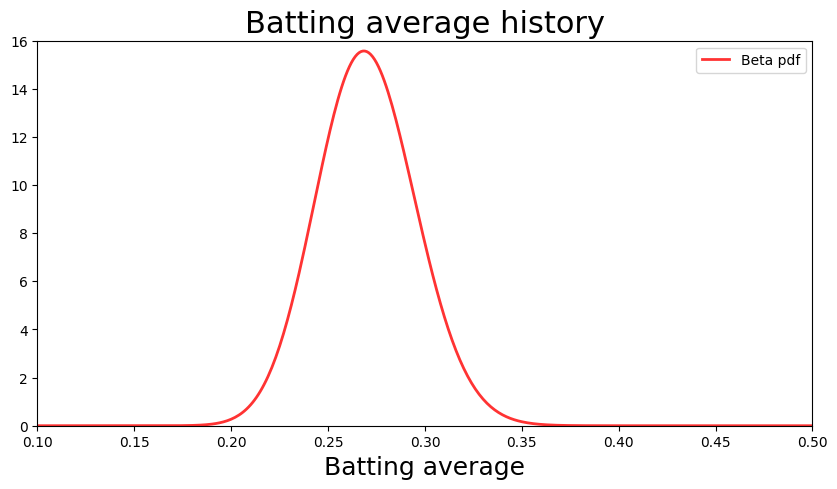

In [3]:
import scipy
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom
from scipy.stats import uniform
from scipy.stats import beta


alpha = 81
beta = 219
a = 0.0
b_minus_a = 1.0
plt.figure(figsize = (10,5))
plt.title('Batting average history', fontsize = 22)
r=np.arange(0.,1.01,.001)
plt.xlim(0.1,0.5)
plt.ylim(0.,16.)
plt.xlabel('Batting average',  fontsize = 18)
plt.plot(r, scipy.stats.beta.pdf(r, alpha, beta), 'r-', lw=2, alpha=0.8, label='Beta pdf')
plt.legend()
plt.savefig('batting_avg.pdf')
plt.show()

## Different priors

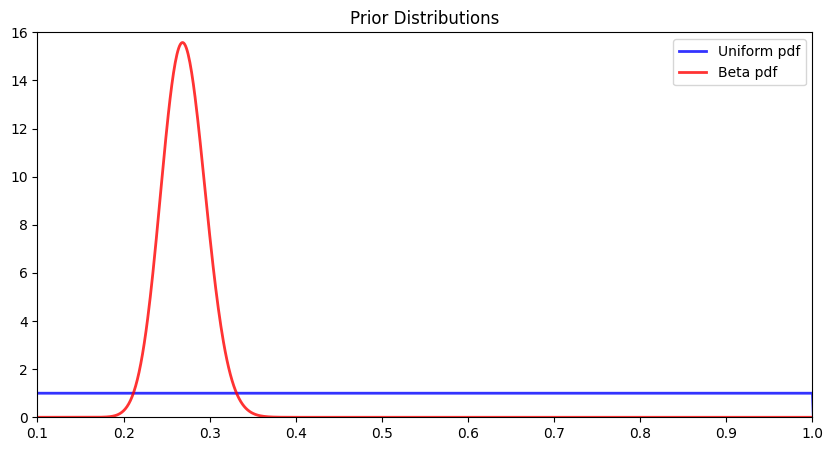

In [3]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom
from scipy.stats import uniform
from scipy.stats import beta


alpha = 81
beta = 219
a = 0.0
b_minus_a = 1.0
plt.figure(figsize = (10,5))
plt.title('Prior Distributions')
r=np.arange(0.,1.01,.001)
plt.xlim(0.1,1)
plt.ylim(0.,16.)
plt.plot(r, scipy.stats.uniform.pdf(r, a, b_minus_a), 'b-', lw=2, alpha=0.8, label='Uniform pdf')
plt.plot(r, scipy.stats.beta.pdf(r, alpha, beta), 'r-', lw=2, alpha=0.8, label='Beta pdf')
plt.legend()
plt.show()

### Both prior and posterior

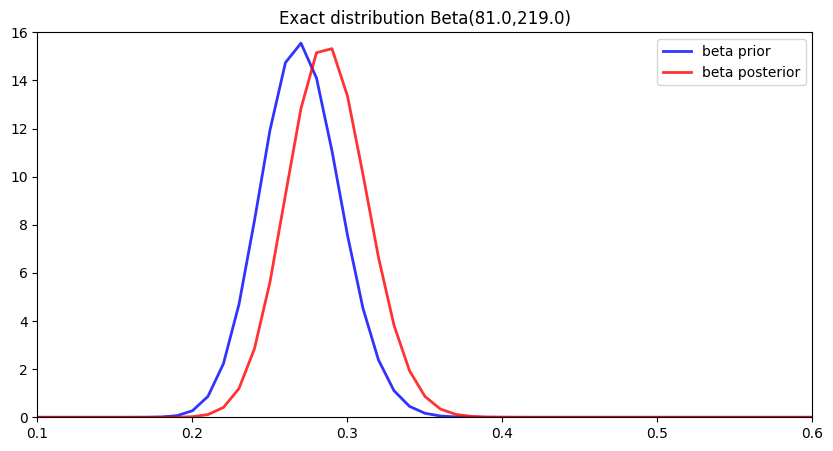

In [5]:
alpha = 81
beta = 219
plt.figure(figsize = (10,5))
plt.title("Exact distribution Beta(%0.1f,%0.1f)"%(alpha,beta))
r=np.arange(0.,1.01,.01)
plt.xlim(0.1,0.6)
plt.ylim(0.,16.)
# plt.hist(samples_for_hist, density = True, bins =30)
plt.plot(r, scipy.stats.beta.pdf(r, alpha, beta), 'b-', lw=2, alpha=0.8, label='beta prior')
plt.plot(r, scipy.stats.beta.pdf(r, alpha+8, beta+2), 'r-', lw=2, alpha=0.8, label='beta posterior')
plt.legend()
plt.show()

## If the true value is 0.8 and we had 800 successes out of 1000.

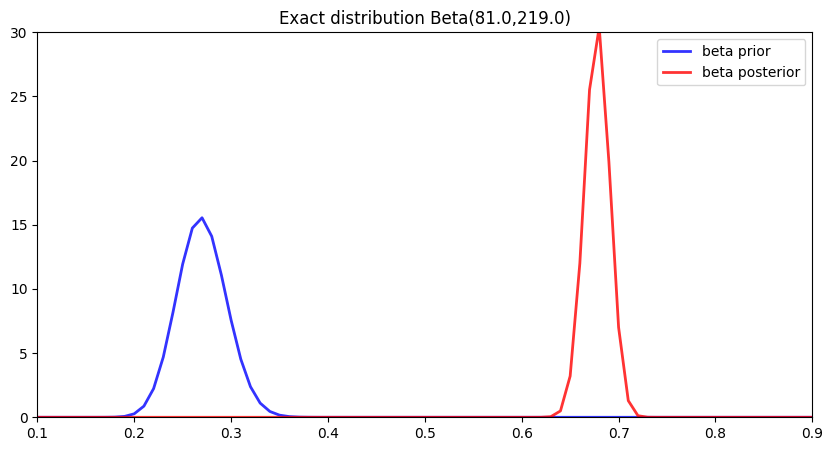

In [6]:

alpha = 81
beta = 219
plt.figure(figsize = (10,5))
plt.title("Exact distribution Beta(%0.1f,%0.1f)"%(alpha,beta))
r=np.arange(0.,1.01,.01)
plt.xlim(0.1,0.9)
plt.ylim(0.,30.)
# plt.hist(samples_for_hist, density = True, bins =30)
plt.plot(r, scipy.stats.beta.pdf(r, alpha, beta), 'b-', lw=2, alpha=0.8, label='beta prior')
plt.plot(r, scipy.stats.beta.pdf(r, alpha+800, beta+200), 'r-', lw=2, alpha=0.8, label='beta posterior')
plt.legend()
plt.show()

### Computing posterior by sampling

### In the baseball example, we knew the distribution of the Posterior.
### We could identify it as Beta distribution
### What happens if this is not the case??
### We try a new approach - sampling from the posterior
### Before we show how it is done, let's see how sampling can get us closer to the distribution.
### Here is an example with exponential distribution.

In [4]:
samples = np.random.exponential(1, 50000)

In [5]:
x_vals = np.linspace(0,7,200)
y_vals = 1*np.exp(-1*x_vals)

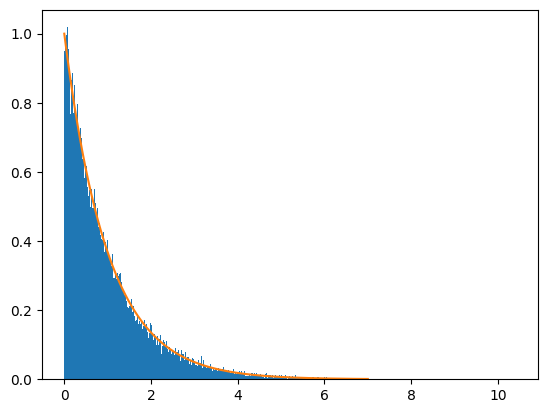

In [6]:
plt.figure()
plt.hist(samples, bins = 750, density = True)
plt.plot(x_vals, y_vals)
plt.show()

## We can derive probabilities using the samples:

### What is the probability of having less than 0.5?

In [7]:
samples[samples<0.5].shape[0]/samples.shape[0]

0.39642

## If we wish to sample a posterior we use the following code:
### Mystirous code which be discussed next lesson

In [8]:
import pymc as pm
###  define a model with a 'with' statement
with pm.Model() as beta_binomial:

    # define prior: define a distribution, and its parameters and give it a name
    theta = pm.Beta('theta', alpha=81, beta=219)

    # define likelihood, just like prior but with an 'observed' argument

    hits = pm.Binomial('hits',n=10, p=theta, observed=4)

    #Sample from the posterior - to be covered later in the course
    baseball_samples = pm.sample(5000)




WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`
WARNING (pytensor.configdefaults): g++ not detected!  PyTensor will be unable to compile C-implementations and will default to Python. Performance may be severely degraded. To remove this warning, set PyTensor flags cxx to an empty string.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [theta]


C:\Users\Eshel\anaconda3\envs\bayes\Lib\site-packages\rich\live.py:231: UserWarning: install "ipywidgets" for 
Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 5_000 draw iterations (4_000 + 20_000 draws total) took 38 seconds.


In [11]:
baseball_samples.posterior

<xarray.Dataset> Size: 200kB
Dimensions:  (chain: 4, draw: 5000)
Coordinates:
  * chain    (chain) int64 32B 0 1 2 3
  * draw     (draw) int64 40kB 0 1 2 3 4 5 6 ... 4994 4995 4996 4997 4998 4999
Data variables:
    theta    (chain, draw) float64 160kB 0.2906 0.2453 0.2558 ... 0.2985 0.2508
Attributes:
    created_at:                 2026-10-13T06:57:43.295882+00:00
    arviz_version:              0.20.0
    inference_library:          pymc
    inference_library_version:  5.21.0
    sampling_time:              34.45821189880371
    tuning_steps:               1000

In [9]:

# Extracting samples
mcmc_data = baseball_samples.posterior['theta']
mcmc_data.shape

(4, 5000)

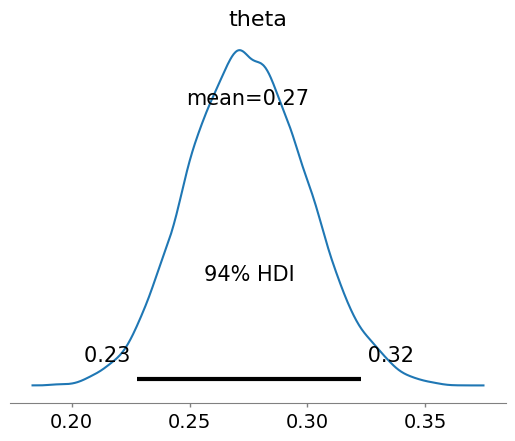

In [10]:
from arviz import plot_posterior
# plot_posterior: this is an arviz funciton that plots posterior function
plot_posterior(baseball_samples, var_names=['theta'],   kind='kde');

###  What is HDI?

HDI is: highest density intreval. This is also considered as the suggested credible interval.

Credible intervals capture our current uncertainty in the location of the parameter values and thus can be interpreted as probabilistic statement about the parameter.

In contrast, confidence intervals (the frequentist approach) capture the uncertainty about the interval we have obtained (i.e., whether it contains the true value or not). Thus, they cannot be interpreted as a probabilistic statement about the true parameter values.

Background

Suppose that you have some data x
 and you are trying to estimate θ
. You have a data generating process that describes how x
 is generated conditional on θ
. In other words you know the distribution of x
 (say, $f(x|θ)$).

_Inference Problem_

Your inference problem is: What values of θ
 are reasonable given the observed data x?

_Confidence Intervals_

Confidence intervals are a classical answer to the above problem. In this approach, you assume that there is true, fixed value of θ
. Given this assumption, you use the data x
 to get to an estimate of θ
 (say, $\hat{θ}$
). Once you have your estimate, you want to assess where the true value is in relation to your estimate.

Notice that under this approach the true value is not a random variable. It is a fixed but unknown quantity. In contrast, your estimate is a random variable as it depends on your data x
 which was generated from your data generating process. Thus, you realize that you get different estimates each time you repeat your study.

The above understanding leads to the following methodology to assess where the true parameter is in relation to your estimate. Define an interval, I≡[lb(x),ub(x)]
 with the following property:

$P(θ∈I)=0.95$

An interval constructed like the above is what is called a confidence interval. Since, the true value is unknown but fixed, the true value is either in the interval or outside the interval. The confidence interval then is a statement about the likelihood that the interval we obtain actually has the true parameter value. Thus, the probability statement is about the interval (i.e., the chances that interval which has the true value or not) rather than about the location of the true parameter value.

In this paradigm, it is meaningless to speak about the probability that a true value is less than or greater than some value as the true value is not a random variable.

_Credible Intervals_

In contrast to the classical approach, in the bayesian approach we assume that the true value is a random variable. Thus, we capture the our uncertainty about the true parameter value by a imposing a prior distribution on the true parameter vector (say f(θ)
).

Using bayes theorem, we construct the posterior distribution for the parameter vector by blending the prior and the data we have (briefly the posterior is f(θ|x)∝f(θ)f(x|θ)
).

We then arrive at a point estimate using the posterior distribution (e.g., use the mean of the posterior distribution). However, since under this paradigm, the true parameter vector is a random variable, we also want to know the extent of uncertainty we have in our point estimate. Thus, we construct an interval such that the following holds:

P(l(θ)≤θ≤ub(θ))=0.95
The above is a credible interval.

_Summary_

Credible intervals capture our current uncertainty in the location of the parameter values and thus can be interpreted as probabilistic statement about the parameter.

In contrast, confidence intervals capture the uncertainty about the interval we have obtained (i.e., whether it contains the true value or not). Thus, they cannot be interpreted as a probabilistic statement about the true parameter values.

## Comparing the posterior sampling against the  true value:

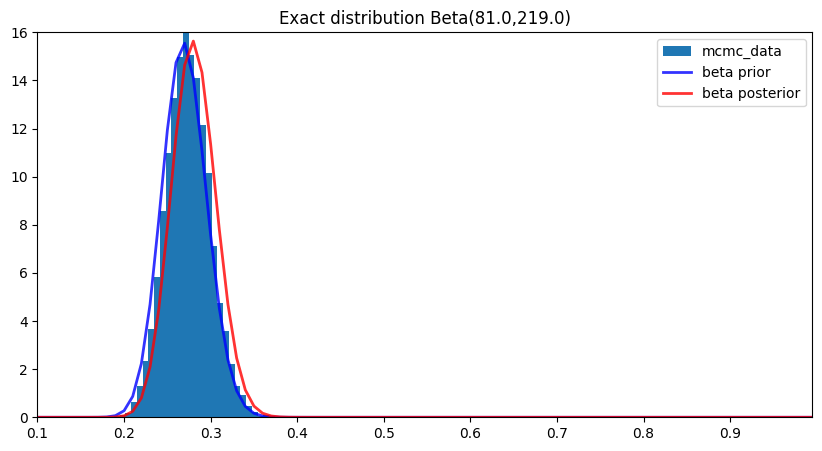

In [14]:
alpha = 81
beta = 219
plt.figure(figsize = (10,5))
plt.title("Exact distribution Beta(%0.1f,%0.1f)"%(alpha,beta))
r=np.arange(0.,1.01,.01)
plt.xlim(0.1,0.995)
plt.ylim(0.,16.)
plt.hist(np.array(mcmc_data).flatten(), density = True, bins =30, alpha = 1.0, label = 'mcmc_data')

plt.plot(r, scipy.stats.beta.pdf(r, alpha, beta), 'b-', lw=2, alpha=0.8, label='beta prior')
plt.plot(r, scipy.stats.beta.pdf(r, alpha+6, beta+4), 'r-', lw=2, alpha=0.8, label='beta posterior')
plt.legend()
plt.show()

## Uniform

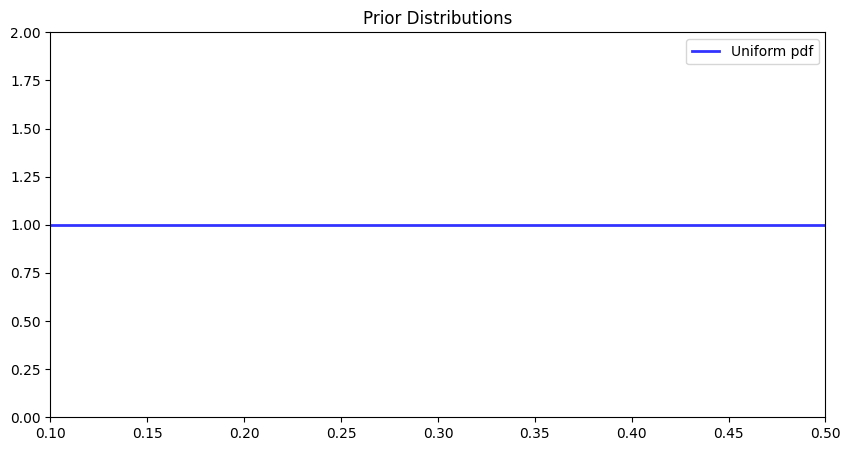

In [15]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom
from scipy.stats import uniform
from scipy.stats import beta



a = 0.0
b_minus_a = 1.0
plt.figure(figsize = (10,5))
plt.title('Prior Distributions')
r=np.arange(0.,1.01,.001)
plt.xlim(0.1,0.5)
plt.ylim(0.,2.)
plt.plot(r, scipy.stats.uniform.pdf(r, a, b_minus_a), 'b-', lw=2, alpha=0.8, label='Uniform pdf')
# plt.plot(r, scipy.stats.beta.pdf(r, alpha, beta), 'r-', lw=2, alpha=0.8, label='Beta pdf')
plt.legend()
plt.show()

In [16]:
from pymc import Uniform
import pymc as pm

with pm.Model() as unifrom_binomial:
    #prior
    theta = pm.Uniform('theta',  lower=0.0, upper=1.0)
    # likelihood
    hits = pm.Binomial('hits',n=10, p=theta, observed=4)
    # sampling
    baseball_samples_uni = pm.sample(5000, tune=1000, cores=2, chains = 4)



Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [theta]


C:\Users\Eshel\anaconda3\envs\bayes\Lib\site-packages\rich\live.py:231: UserWarning: install "ipywidgets" for 
Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 5_000 draw iterations (4_000 + 20_000 draws total) took 59 seconds.


In [17]:
# from pymc import trace

samples_for_hist_uniform = baseball_samples_uni.posterior['theta']
samples_for_hist_uniform.shape

(4, 5000)

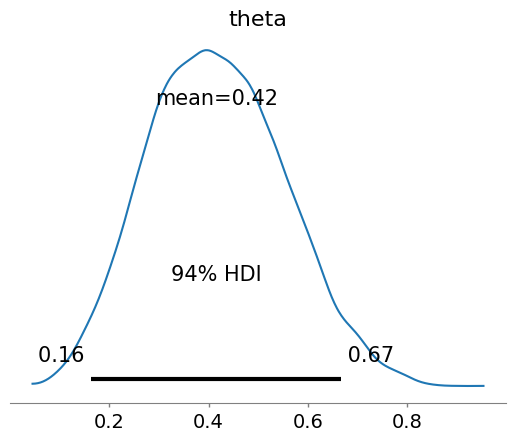

In [18]:
plot_posterior(baseball_samples_uni, var_names=['theta'],   kind='kde');

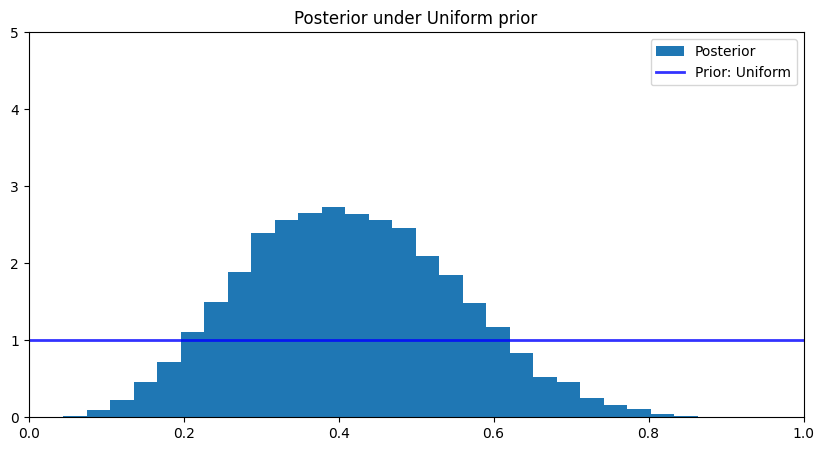

In [19]:
n = 10
y = 8
alpha_uni = n+1
beta_uni = n-y+1
alpha = 81
beta = 219

plt.figure(figsize = (10,5))
plt.title("Posterior under Uniform prior")
r=np.arange(0.,1.01,.01)
plt.xlim(0.0,1)
plt.ylim(0.,5.)
plt.hist(np.array(samples_for_hist_uniform).flatten(), density = True, bins =30, label='Posterior')
plt.plot(r, scipy.stats.uniform.pdf(r, a, b_minus_a), 'b-', lw=2, alpha=0.8, label='Prior: Uniform')
plt.legend()
plt.show()

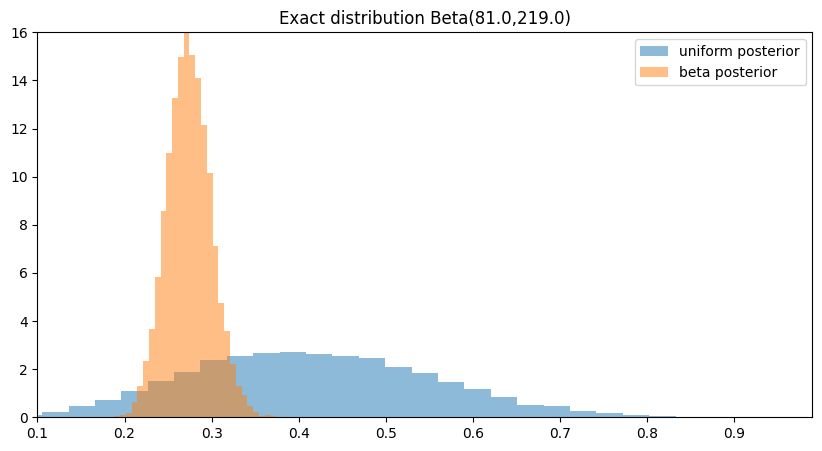

In [20]:
plt.figure(figsize = (10,5))
plt.title("Exact distribution Beta(%0.1f,%0.1f)"%(alpha,beta))
r=np.arange(0.,1.01,.01)
plt.xlim(0.1,0.99)
plt.ylim(0.,16.)
plt.hist(np.array(samples_for_hist_uniform).flatten(), density = True, bins =30, label = 'uniform posterior', alpha = 0.5)
plt.hist(np.array(mcmc_data).flatten(), density = True, bins =30, label = 'beta posterior', alpha = 0.5)
# plt.plot(r, scipy.stats.beta.pdf(r, alpha+8, beta+2), 'r-', lw=2, alpha=0.8, label='beta posterior')
plt.legend()
plt.show()

## What can we do with the posterior distributions?

We can try to first to evaluate the mean value of each posterior.

In [23]:
samples_for_hist_uniform.shape

(2, 5000)

## Mean values:

#### Uniform prior

In [24]:
np.array(samples_for_hist_uniform).flatten().mean()

np.float64(0.4161918314145535)

### Beta prior

In [25]:
np.array(mcmc_data).mean()

np.float64(0.27434835544275465)

### While using two different prior and a very small size of data, we get totally different values.

### Lets check the domains of both priors
### Uniform:

In [26]:
np.array(samples_for_hist_uniform).min().item(), np.array(samples_for_hist_uniform).max().item()

(0.05742231078082061, 0.8646568952756505)

### Beta:

In [27]:
np.array(mcmc_data).min().item(),  np.array(mcmc_data).max().item()

(0.17374192813662842, 0.38373256196914823)

## The effect of the data size

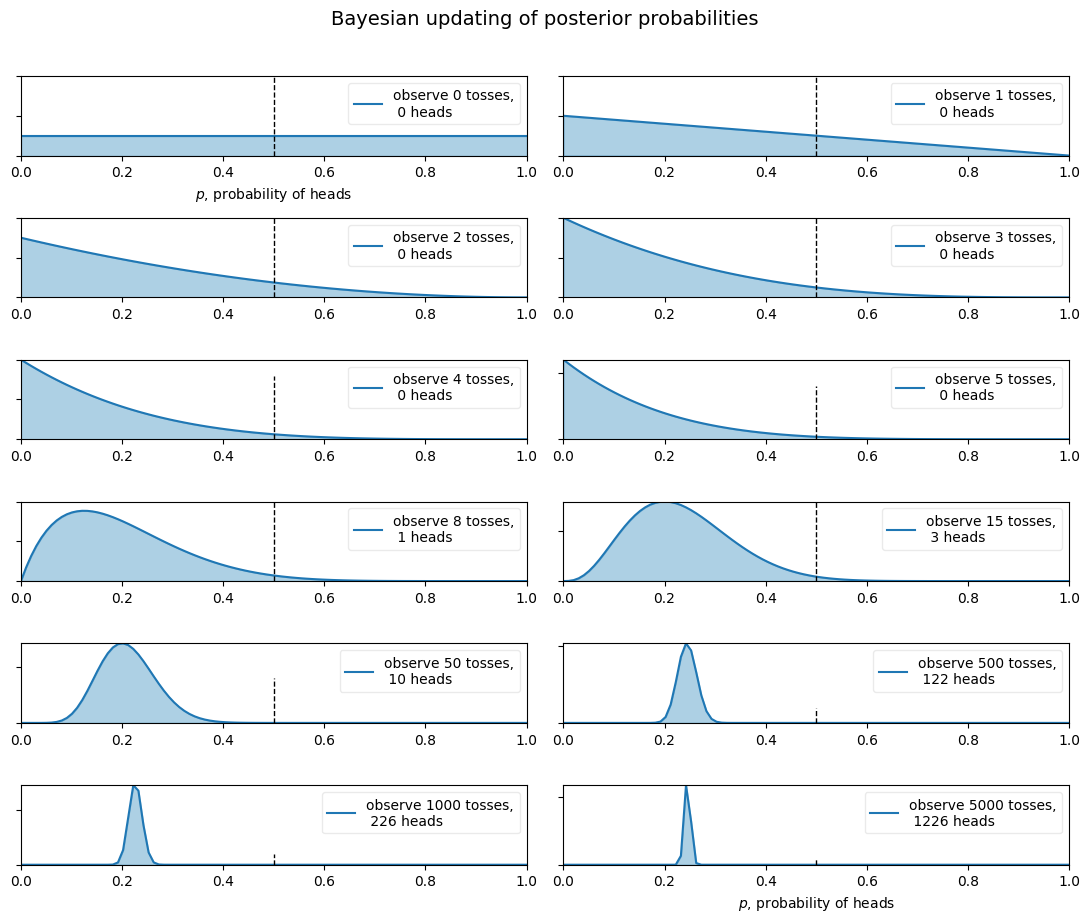

In [31]:
%matplotlib inline
from IPython.core.pylabtools import figsize
import numpy as np
from matplotlib import pyplot as plt
figsize(11, 9)

import scipy.stats as stats

dist = stats.beta
n_trials = [0, 1, 2, 3, 4, 5, 8, 15, 50, 500, 1000, 5000]
data = stats.bernoulli.rvs(0.25, size=n_trials[-1])
x = np.linspace(0, 1, 100)

# For the already prepared, I'm using Binomial's conj. prior.
for k, N in enumerate(n_trials):
    sx = plt.subplot(len(n_trials)//2, 2, k+1)
    plt.xlabel("$p$, probability of heads") \
        if k in [0, len(n_trials)-1] else None
    plt.setp(sx.get_yticklabels(), visible=False)
    heads = data[:N].sum()
    y = dist.pdf(x, 1 + heads, 1 + N - heads)
    plt.plot(x, y, label="observe %d tosses,\n %d heads" % (N, heads))
    plt.fill_between(x, 0, y, color="#348ABD", alpha=0.4)
    plt.vlines(0.5, 0, 4, color="k", linestyles="--", lw=1)

    leg = plt.legend()
    leg.get_frame().set_alpha(0.4)
    plt.autoscale(tight=True)


plt.suptitle("Bayesian updating of posterior probabilities",
             y=1.02,
             fontsize=14)

plt.tight_layout()

## Lets redo the baseball example but with 5000 trials and 1750 succes
### Now lets assume the uniform prior is between 0.2 to 0.35 (as prior baseball knlowledge tells us).

In [36]:
n_trials = 5000
succses = 1750

with pm.Model() as beta_binomial:

    b = pm.Beta('b', alpha=81, beta=219)
    hits = pm.Binomial('hits',n=n_trials, p=b, observed=succses)

    baseball_samples = pm.sample(5000, tune=1000, cores=1)

samples_for_hist =  np.array(baseball_samples.posterior['b']).flatten()

with pm.Model() as unifrom_binomial:

    b = pm.Uniform('u',  lower=0.00, upper=1.00)
    hits = pm.Binomial('hits',n=n_trials, p=b, observed=succses)

    baseball_samples_uni = pm.sample(5000, tune=100, cores=1)

samples_for_hist_uniform = np.array(baseball_samples_uni.posterior['u']).flatten()




Initializing NUTS using jitter+adapt_diag...
Sequential sampling (2 chains in 1 job)
NUTS: [b]


C:\Users\Eshel\anaconda3\envs\bayes\Lib\site-packages\rich\live.py:231: UserWarning: install "ipywidgets" for 
Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

C:\Users\Eshel\anaconda3\envs\bayes\Lib\site-packages\pytensor\scalar\basic.py:2106: RuntimeWarning: divide by zero
encountered in divide
  return x / y

C:\Users\Eshel\anaconda3\envs\bayes\Lib\site-packages\numpy\_core\fromnumeric.py:86: RuntimeWarning: invalid value 
encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)

Sampling 2 chains for 1_000 tune and 5_000 draw iterations (2_000 + 10_000 draws total) took 9 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics
Initializing NUTS using jitter+adapt_diag...
Sequential sampling (2 chains in 1 job)
NUTS: [u]


C:\Users\Eshel\anaconda3\envs\bayes\Lib\site-packages\rich\live.py:231: UserWarning: install "ipywidgets" for 
Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 2 chains for 100 tune and 5_000 draw iterations (200 + 10_000 draws total) took 7 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics


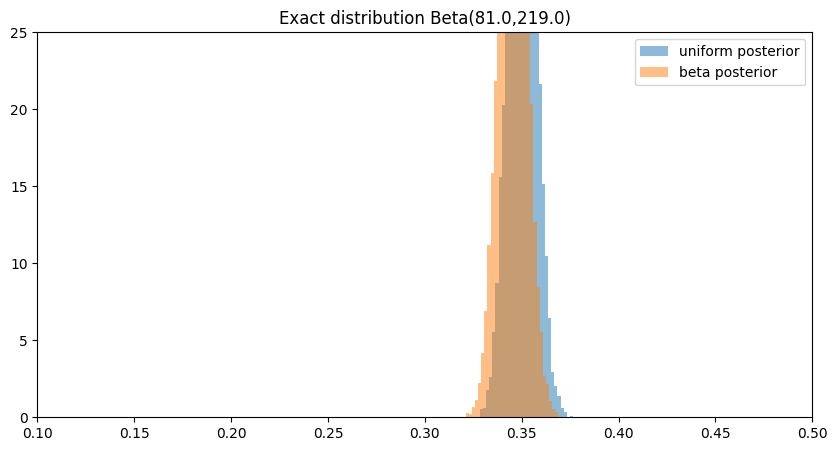

In [37]:
plt.figure(figsize = (10,5))
plt.title("Exact distribution Beta(%0.1f,%0.1f)"%(alpha,beta))
r=np.arange(0.,1.01,.01)
plt.xlim(0.1,0.5)
plt.ylim(0.,25.)
plt.hist(samples_for_hist_uniform, density = True, bins =30, label = 'uniform posterior', alpha = 0.5)
plt.hist(samples_for_hist, density = True, bins =30, label = 'beta posterior', alpha = 0.5)
plt.legend()
plt.show()

## Now the posteriors look similar.
### That is, the larger the data set the less effect the prior has

### Posterior expected value Beta analysis

### The expected value of the posterior is:

## $$ E[\theta | Y] = \frac{\alpha + y}{n+\alpha + \beta}, $$

## where $n$ is the number if trial, $y$ number of success out of the $n$ trials, $\alpha$ and $\beta$ are the prior parameters. 

In [21]:
def get_expceted_val(alpha, beta, n,y):
    return (alpha+y)/(alpha + beta+ n)

In [22]:
alpha1, beta1 = 1 ,1
alpha2, beta2 = 100 ,100
res1 = []
res2 = []

for n in np.arange(10, 10000):
    res1.append(get_expceted_val(alpha1, beta1, n, np.random.binomial(n, 0.8)))
    res2.append(get_expceted_val(alpha2, beta2, n, np.random.binomial(n, 0.8)))

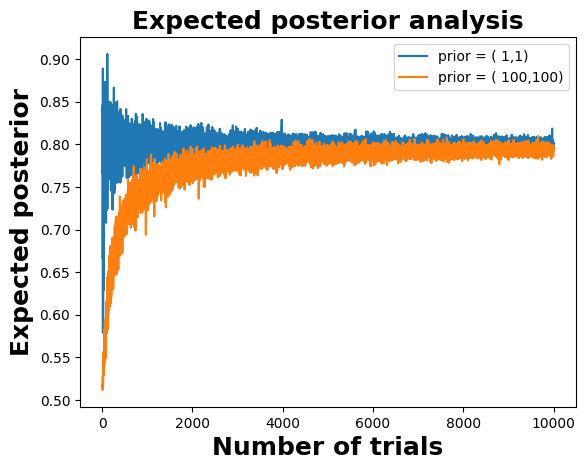

In [23]:
plt.figure()
plt.plot(np.arange(10, 10000), res1, label = 'prior = ( 1,1)')
plt.plot(np.arange(10, 10000), res2, label = 'prior = ( 100,100)')
plt.xlabel('Number of trials', fontsize = 18, fontweight = 'bold')
plt.ylabel('Expected posterior', fontsize = 18, fontweight = 'bold')
plt.title('Expected posterior analysis', fontsize = 18, fontweight = 'bold')
plt.legend()
plt.show()